## DRAGON  REAL ESTATE PRICE PREDICTOR

In [2]:
import pandas as pd
import numpy as np

In [3]:
housing = pd.read_csv("data.csv")
housing.head()


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,NaN,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [4]:
housing.tail()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,393.45,6.48,22.0
505,0.04741,0.0,11.93,0,0.573,6.030,80.8,2.5050,1,273,21.0,396.90,7.88,11.9


In [5]:
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       496 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


In [6]:
housing['CHAS'].value_counts()

CHAS
0    471
1     35
Name: count, dtype: int64

In [7]:
housing.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,496.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.280770,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.703216,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.883000,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.205000,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.618250,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [8]:
## for  reading histogram purpose

# %matplotlib inline
# import matplotlib.pyplot as plt
# housing.hist(bins=50, figsize=(20,15))

## Tain-Test Splitting
```without sklearn kiya hai mannuly kiya hai iske liye sklern me ek fun hai usse krenge aage ham okay bro ```

In [9]:
# # For  Learning Purpose Only
# import numpy as np
# def split_train_test(data,test_ratio):
#     np.random.seed(42)
#     shuffled = np.random.permutation(len(data))
#     # print(shuffled)
#     test_set_size = int(len(data)*  test_ratio)
#     test_indices  =shuffled[:test_set_size]
#     train_indices = shuffled[test_set_size:]
#     return data.iloc[train_indices] , data.iloc[test_indices]
# train_set, test_set = split_train_test(housing,0.2)
# print(f"row in train set:{len(train_set)}\n row in test set {len(test_set)}")

## From sciket learn

In [10]:
# # without StratifiedShuffleSplit

# from sklearn.model_selection import train_test_split
# train_set,test_set  = train_test_split(housing,test_size= 0.2,random_state=42)
# print(f"row in train set:{len(train_set)}\n row in test set {len(test_set)}")

In [11]:
from sklearn.model_selection import StratifiedShuffleSplit

split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

for train_index, test_index in split.split(housing, housing['CHAS']):
    strat_train_set = housing.loc[train_index]
    strat_test_set = housing.loc[test_index]

In [12]:
housing = strat_train_set.copy()

## Looking for Correlations

In [13]:
corr_matrix = housing.corr()
corr_matrix['MEDV'].sort_values(ascending=False)

MEDV       1.000000
RM         0.678923
B          0.361761
ZN         0.339741
DIS        0.240451
CHAS       0.205066
AGE       -0.364596
RAD       -0.374693
CRIM      -0.393715
NOX       -0.422873
TAX       -0.456657
INDUS     -0.473516
PTRATIO   -0.493534
LSTAT     -0.740494
Name: MEDV, dtype: float64

In [14]:
# from pandas.plotting import  scatter_matrix
# Attributes = ['MEDV','RM','ZN','LSTAT']
# scatter_matrix(housing[Attributes],figsize=(12,8))

In [15]:
# housing.plot(kind = "scatter",x="RM",y = 'MEDV',alpha = 0.8)

##  Try Attributes combinations

In [16]:
housing['TAXRM'] = housing['TAX']/housing['RM']
housing.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV,TAXRM
254,0.04819,80.0,3.64,0,0.392,6.108,32.0,9.2203,1,315,16.4,392.89,6.57,21.9,51.571709
348,0.01501,80.0,2.01,0,0.435,6.635,29.7,8.3440,4,280,17.0,390.94,5.99,24.5,42.200452
476,4.87141,0.0,18.10,0,0.614,6.484,93.6,2.3053,24,666,20.2,396.21,18.68,16.7,102.714374
321,0.18159,0.0,7.38,0,0.493,6.376,54.3,4.5404,5,287,19.6,396.90,6.87,23.1,45.012547
326,0.30347,0.0,7.38,0,0.493,6.312,28.9,5.4159,5,287,19.6,396.90,6.15,23.0,45.468948


In [17]:
corr_matrix = housing.corr()
corr_matrix['MEDV'].sort_values(ascending=False)

MEDV       1.000000
RM         0.678923
B          0.361761
ZN         0.339741
DIS        0.240451
CHAS       0.205066
AGE       -0.364596
RAD       -0.374693
CRIM      -0.393715
NOX       -0.422873
TAX       -0.456657
INDUS     -0.473516
PTRATIO   -0.493534
TAXRM     -0.525744
LSTAT     -0.740494
Name: MEDV, dtype: float64

<Axes: xlabel='TAXRM', ylabel='MEDV'>

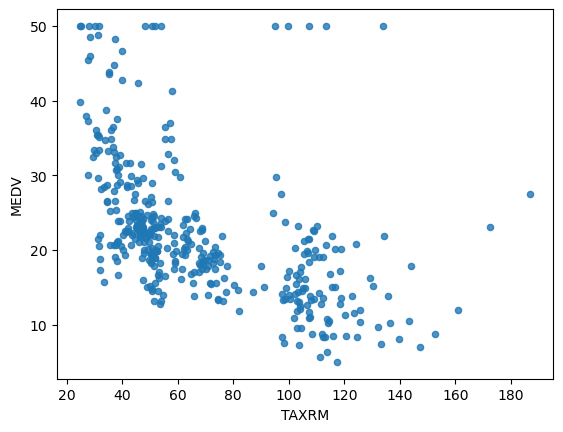

In [18]:
housing.plot(kind = "scatter",x="TAXRM",y = 'MEDV',alpha = 0.8)

In [19]:
housing = strat_train_set.drop('MEDV',axis=1)
housing_labels = strat_train_set['MEDV'].copy()

## MISSING ATTRIBUTES

##### To take care of missing attributes, you have three option:
- ```1.get rid of the missing data point```
- ```2.get rid of the whole attribues```
- ```3.set the value to some values(0,mean or median)[Recomanded] ``` 

In [20]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')
imputer.fit(housing)

,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False


In [21]:
imputer.statistics_.shape

(13,)

In [22]:
x = imputer.transform(housing)
housing_tr = pd.DataFrame(x,columns= housing.columns)
housing_tr.describe()          #only for showcase

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
count,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000
mean,3.602814,10.836634,11.344950,0.069307,0.558064,6.276807,69.039851,3.746210,9.735149,412.341584,18.473267,353.392822,12.791609
std,8.099383,22.150636,6.877817,0.254290,0.116875,0.709757,28.258248,2.099057,8.731259,168.672623,2.129243,96.069235,7.235740
min,0.006320,0.000000,0.740000,0.000000,0.389000,3.561000,2.900000,1.129600,1.000000,187.000000,13.000000,0.320000,1.730000
25%,0.086962,0.000000,5.190000,0.000000,0.453000,5.879750,44.850000,2.035975,4.000000,284.000000,17.400000,374.617500,6.847500
50%,0.286735,0.000000,9.900000,0.000000,0.538000,6.209000,78.200000,3.122200,5.000000,337.000000,19.000000,390.955000,11.570000
75%,3.731923,12.500000,18.100000,0.000000,0.631000,6.626000,94.100000,5.100400,24.000000,666.000000,20.200000,395.630000,17.102500
max,73.534100,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,36.980000


### Scikit-learn Desgin

Primarily, three types of object in scikit learn
1. Estimators - It Estimates some parameter based on a dataset. Eg. imputer
It has a fit method and transform method.
fit method - fits the  datasets & caclultes parameters

2. Transformers - transform methos takes input and returns output based on the learnings from fit(). It also has a convenience function called fit_transform() which fit and then transform
3. Predictors - LinearRegression model is an example of predicotrs. fit() and predcit() are twoo common function.  it also gives score() fucntion which will evalute the predicitions


## Feature Scalling
- two type of feature scaling methods:
- 1. MIn-max scallng (Normlization)
    ```(value-min)/(max-min)```
- 2. standardization
    ```(value-mean)/std```

- SKlearn provides a class called Standard  Scaler for this

## Creating a Pipeline

In [23]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

my_pipeline = Pipeline([
    ('imputer',SimpleImputer(strategy = 'median')),
    ('std_scalled',StandardScaler())

])

housing_num_tr = my_pipeline.fit_transform(housing)
housing_num_tr.shape


(404, 13)

## Selecting a desired Model for Dragon Real Estates

In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
# model = LinearRegression()
model = RandomForestRegressor()
# model  = DecisionTreeRegressor()
model.fit(housing_num_tr,housing_labels)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [25]:
some_data = housing.iloc[:5]
some_labels = housing_labels[:5]

prepared_data = my_pipeline.transform(some_data)
model.predict(prepared_data)

array([22.248, 25.404, 16.525, 23.32 , 23.641])

## Evaluating the model

In [26]:
# # for LinearRegression
# from  sklearn.metrics import mean_squared_error
# housing_predictions = model.predict(housing_num_tr)
# lin_mse = mean_squared_error(housing_labels,housing_predictions)
# lin_rmse = np.sqrt(lin_mse)
# lin_mse

In [27]:
# for DecisionTreeRegressor()
from  sklearn.metrics import mean_squared_error
housing_predictions = model.predict(housing_num_tr)
mse = mean_squared_error(housing_labels,housing_predictions)
rmse = np.sqrt(mse)
rmse

np.float64(1.2256240620941468)

### Using better evaluation technique- Cross Validation

In [28]:
from sklearn.model_selection import cross_val_score
import numpy as np

score = cross_val_score(
    model,
    housing_num_tr,
    housing_labels,
    scoring='neg_mean_squared_error',  
    cv=10                               
)

rmse_score = np.sqrt(-score)
rmse_score

array([2.90864241, 2.77454051, 4.57949706, 2.73722709, 3.2886545 ,
       2.46338537, 4.75434171, 3.72260273, 3.22979736, 3.35035716])

In [29]:
def print_score(scores):
    print(f"Scores:{scores}")
    print(f"Mean:{scores.mean()}")
    print(f"Standard deviation:{scores.std()}")

print_score(rmse_score)

Scores:[2.90864241 2.77454051 4.57949706 2.73722709 3.2886545  2.46338537
 4.75434171 3.72260273 3.22979736 3.35035716]
Mean:3.380904591436844
Standard deviation:0.7293050720469866


## Saving the Model

In [30]:
from joblib import dump,load
dump(model,"Dragon.joblib")

['Dragon.joblib']

## Testing the model on test data

In [35]:
x_test = strat_test_set.drop("MEDV",axis=1)
y_test = strat_test_set["MEDV"].copy()
x_test_prepared = my_pipeline.transform(x_test)
final_predictions = model.predict(x_test_prepared)
final_mse = mean_squared_error(y_test,final_predictions)
final_rmse = np.sqrt(final_mse)
print(final_predictions,list(y_test))


[24.413 11.6   25.174 21.622 18.623 15.11  20.211 14.753 32.327 42.676
 19.559 11.73  24.643 27.239 19.659 11.006 32.27  14.338 23.497 19.048
 19.925 17.905 17.295 21.717 18.943 31.454 16.266 33.168  8.903 33.296
 23.894 21.393 23.468 11.126 20.787 11.354 44.412 24.64  24.765 41.374
 24.244 29.55  20.149 20.942 19.023 33.693 44.688 20.187 20.436 21.968
 21.608 14.636 20.916 15.13  24.588 32.45  40.532 28.62  19.315 21.031
 28.858  9.538 18.762 27.919 14.655 32.473 19.599 17.736 18.898 33.505
 26.236 22.914 21.681 22.29  34.313 12.598 15.967 19.888 21.21  21.367
 23.135 21.828 14.51  23.096 21.275 21.434 13.715 20.965 22.996 23.614
 18.823 27.626  7.293 26.243 19.029 30.092 19.762 30.697 14.527 27.398
 21.438 20.024] [16.5, 10.2, 30.1, 23.0, 14.4, 15.6, 19.4, 14.1, 30.3, 35.2, 23.1, 13.8, 25.0, 27.9, 19.5, 12.3, 32.2, 13.5, 23.8, 21.7, 19.2, 19.5, 10.4, 23.2, 18.6, 28.5, 15.2, 32.0, 7.2, 34.6, 20.1, 20.6, 23.6, 13.1, 23.8, 12.7, 43.1, 24.7, 22.2, 44.0, 28.1, 31.0, 21.7, 23.4, 19.5, 33.1

In [38]:
prepared_data[0]

array([-0.43942006,  3.12628155, -1.12165014, -0.27288841, -1.42262747,
       -0.2381325 , -1.31238772,  2.61111401, -1.0016859 , -0.5778192 ,
       -0.97491834,  0.41164221, -0.86091034])